# Test de la partie preprocessing pour les données audio

## Test Mel-spectrogram

In [6]:
import sys
import os

sys.path.append(os.path.abspath("../src"))

In [7]:
import yaml
import librosa

In [9]:
# Test the mel-spectrogram extraction
import numpy as np
from preprocessing.audio_utils import AudioPipeline
import matplotlib.pyplot as plt


In [10]:
conf_path = "C:\\Users\\sysadmin\\Documents\\stage\\Edge AI\\KWS\\52-Hertz-KWS\\configuration\\config.yaml"
audio_path = "C:\\Users\\sysadmin\\Documents\\stage\\Edge AI\\KWS\\52-Hertz-KWS\\data\\raw\\talky\\SPEAK35.wav.6p3trn79.ingestion-7f57cc555d-b2hjl.s8.wav"

pipeline = AudioPipeline(conf_path)
with open(conf_path, "r") as f:
    yaml.safe_load(f)

# tracer Mel Spectrogram feature extraction
def test_mel_extraction():

    # Load a sample audio file
    audio = pipeline.load_audio(audio_path)
    # Load log mel from path 
    log_mel = pipeline.extract_log_mel_from_path(audio_path, augment=False)
    return log_mel

In [11]:
print (len(pipeline.load_audio(audio_path)))

16000


In [12]:
test = test_mel_extraction()

In [13]:
print (test)
print(test.shape)

[[[ 1.2681997 ]
  [ 1.295459  ]
  [ 1.2939188 ]
  ...
  [ 1.2885265 ]
  [ 1.2992611 ]
  [ 1.0680677 ]]

 [[ 0.70973736]
  [-1.1754388 ]
  [-0.93625194]
  ...
  [-0.86815286]
  [-0.42021915]
  [ 0.25409043]]

 [[ 0.371414  ]
  [-1.0239599 ]
  [-0.8373631 ]
  ...
  [-1.0667521 ]
  [-0.53037554]
  [ 0.3665881 ]]

 ...

 [[-0.7445811 ]
  [-0.75079775]
  [-0.5097901 ]
  ...
  [-0.6826096 ]
  [-0.68752646]
  [-0.5980246 ]]

 [[-1.0690215 ]
  [-0.8160712 ]
  [-0.8762381 ]
  ...
  [-0.82617116]
  [-0.6968104 ]
  [-1.0192268 ]]

 [[-1.0301093 ]
  [-0.7450626 ]
  [-0.77884495]
  ...
  [-0.7854717 ]
  [-0.8215962 ]
  [-1.0411806 ]]]
(64, 50, 1)


## Plot the result

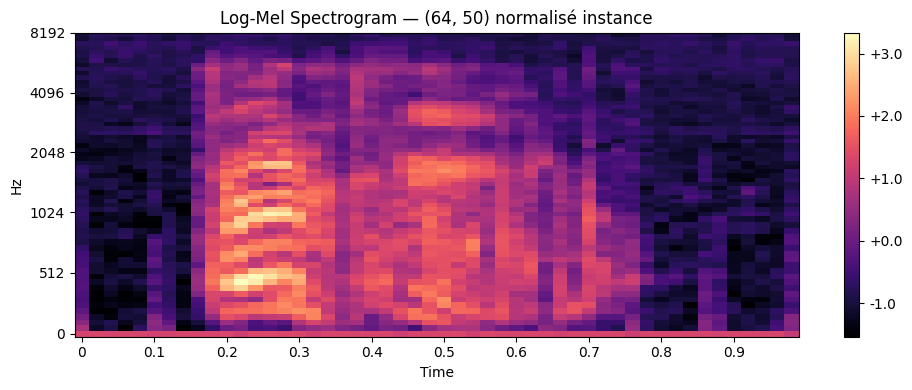

In [19]:
log_mel = test_mel_extraction().squeeze()  # [64, 50, 1] -> [64, 50]

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    log_mel,
    sr=pipeline.sample_rate,
    hop_length=pipeline.hop_length,
    x_axis="time",
    y_axis="mel",
    fmin=pipeline.fmin,
    fmax=pipeline.fmax,
    cmap="magma",
)
plt.colorbar(format="%+.1f")
plt.title(f"Log-Mel Spectrogram — {log_mel.shape} normalisé instance")
plt.tight_layout()
plt.show()

## Test the input of the yamnet 

In [19]:
conf_path_yamnet = "C:\\Users\\sysadmin\\Documents\\stage\\Edge AI\\KWS\\52-Hertz-KWS\\configuration\\config_yamnet.yaml"
audio_path2 = "C:\\Users\\sysadmin\\Documents\\stage\\Edge AI\\KWS\\52-Hertz-KWS\\data\\raw\\talky\\SPEAK35.wav.6p3trn79.ingestion-7f57cc555d-b2hjl.s5.wav"

pipeline = AudioPipeline(conf_path_yamnet)
with open(conf_path, "r") as f:
    yaml.safe_load(f)

# tracer Mel Spectrogram feature extraction
def test_mel_extraction():

    # Load a sample audio file
    audio = pipeline.load_audio(audio_path2)
    # Load log mel from path 
    log_mel = pipeline.extract_log_mel_from_path(audio_path2, augment=False)
    return log_mel

In [21]:
print (len(pipeline.load_audio(audio_path2)))

16000


In [22]:
test = test_mel_extraction()
print (test)
print(test.shape)

[[[-1.7179811 ]
  [-1.5504289 ]
  [-1.7169833 ]
  ...
  [-1.1746614 ]
  [-1.2111025 ]
  [-1.3021222 ]]

 [[-1.4674932 ]
  [-1.5626311 ]
  [-1.3247521 ]
  ...
  [-0.9346865 ]
  [-1.3449409 ]
  [-0.94558734]]

 [[-1.211233  ]
  [-1.4449638 ]
  [-1.0008745 ]
  ...
  [-0.46284044]
  [-0.8521009 ]
  [-0.73986167]]

 ...

 [[-0.8899173 ]
  [-1.0903345 ]
  [-0.97620827]
  ...
  [-1.2354913 ]
  [-1.1179742 ]
  [-1.1444771 ]]

 [[-1.0176785 ]
  [-1.049565  ]
  [-1.0209671 ]
  ...
  [-1.1590685 ]
  [-0.9186962 ]
  [-1.1130182 ]]

 [[-1.1159654 ]
  [-0.936494  ]
  [-1.1080108 ]
  ...
  [-1.1753408 ]
  [-1.108231  ]
  [-1.2850742 ]]]
(64, 90, 1)


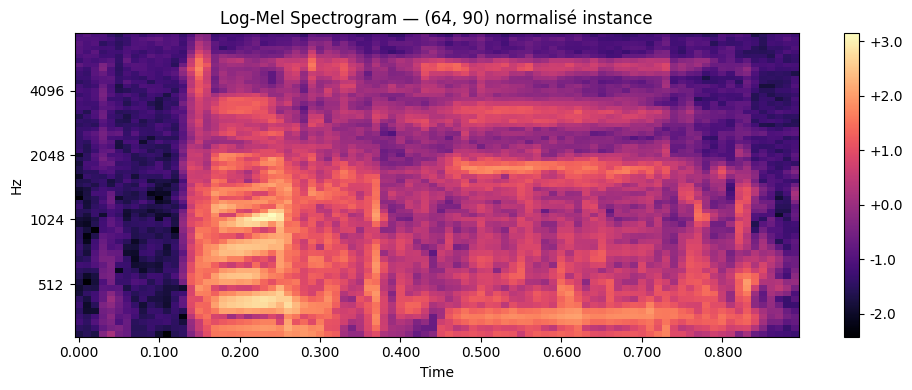

In [23]:
log_mel = test_mel_extraction().squeeze()  

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    log_mel,
    sr=pipeline.sample_rate,
    hop_length=pipeline.hop_length,
    x_axis="time",
    y_axis="mel",
    fmin=pipeline.fmin,
    fmax=pipeline.fmax,
    cmap="magma",
)
plt.colorbar(format="%+.1f")
plt.title(f"Log-Mel Spectrogram — {log_mel.shape} normalisé instance")
plt.tight_layout()
plt.show()